<a href="https://colab.research.google.com/github/Dishantchd/DS-practical/blob/main/Ds_practical8/pima_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Tree on Pima Indians Diabetes Data



## 1. Imports

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.feature_selection import mutual_info_classif

In [ ]:


try:
    url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
    df = pd.read_csv(url)
    print("Loaded from URL")
except Exception as e:
    print("URL failed:", e)

print(df.shape)
df.head()

Loaded from URL
(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Inspect the data

In [ ]:
print(df.describe())
print("\nClass balance:\n", df["Outcome"].value_counts())
print("\nZeros per column:\n", (df == 0).sum())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [ ]:
cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
df[cols] = df[cols].replace(0, np.nan)
df[cols] = df[cols].fillna(df[cols].median())
print(df[cols].isna().sum())

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


## 5. Target and features

In [ ]:
X = df.drop("Outcome", axis=1)   # independent variables (features)
y = df["Outcome"]                # dependent variable (target)
print("Features:", list(X.columns))
print("Target  : Outcome")

Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target  : Outcome


## 6. Split the data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (614, 8) Test: (154, 8)


## 7. Extra feature selection checks


In [ ]:
mi = pd.Series(mutual_info_classif(X_train, y_train, random_state=42), index=X.columns)
print("Mutual information:\n", mi.sort_values(ascending=False))

corr = pd.concat([X_train, y_train], axis=1).corr()["Outcome"].drop("Outcome")
print("\nCorrelation with Outcome:\n", corr.sort_values(ascending=False))

Mutual information:
 Glucose                     0.117706
BMI                         0.088717
Age                         0.062202
Insulin                     0.043321
Pregnancies                 0.038053
SkinThickness               0.033670
BloodPressure               0.020999
DiabetesPedigreeFunction    0.006189
dtype: float64

Correlation with Outcome:
 Glucose                     0.512291
BMI                         0.328830
Insulin                     0.245902
Age                         0.240676
SkinThickness               0.234260
Pregnancies                 0.208173
BloodPressure               0.183373
DiabetesPedigreeFunction    0.165312
Name: Outcome, dtype: float64


## 8. Build the decision tree (Entropy and Gini)

In [ ]:
def evaluate(criterion, depth):
    m = DecisionTreeClassifier(criterion=criterion, max_depth=depth, random_state=42)
    m.fit(X_train, y_train)
    tr = accuracy_score(y_train, m.predict(X_train))
    te = accuracy_score(y_test, m.predict(X_test))
    return m, tr, te

rows = []
for crit in ["entropy", "gini"]:
    for d in [2, 3, 4, 5, 6, None]:
        _, tr, te = evaluate(crit, d)
        rows.append([crit, d, round(tr,3), round(te,3)])
print(pd.DataFrame(rows, columns=["Criterion","Max depth","Train acc","Test acc"]))

   Criterion  Max depth  Train acc  Test acc
0    entropy        2.0      0.764     0.688
1    entropy        3.0      0.767     0.688
2    entropy        4.0      0.777     0.792
3    entropy        5.0      0.796     0.682
4    entropy        6.0      0.839     0.747
5    entropy        NaN      1.000     0.675
6       gini        2.0      0.764     0.688
7       gini        3.0      0.769     0.688
8       gini        4.0      0.795     0.786
9       gini        5.0      0.814     0.760
10      gini        6.0      0.850     0.747
11      gini        NaN      1.000     0.682


In [ ]:

clf, tr, te = evaluate("entropy", 3)
y_pred = clf.predict(X_test)
print("Train accuracy:", round(tr,3), "| Test accuracy:", round(te,3))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred, target_names=["No Diabetes","Diabetes"]))

Train accuracy: 0.767 | Test accuracy: 0.688

Confusion matrix:
 [[92  8]
 [40 14]]

               precision    recall  f1-score   support

 No Diabetes       0.70      0.92      0.79       100
    Diabetes       0.64      0.26      0.37        54

    accuracy                           0.69       154
   macro avg       0.67      0.59      0.58       154
weighted avg       0.68      0.69      0.64       154



## 9. Visualize the tree

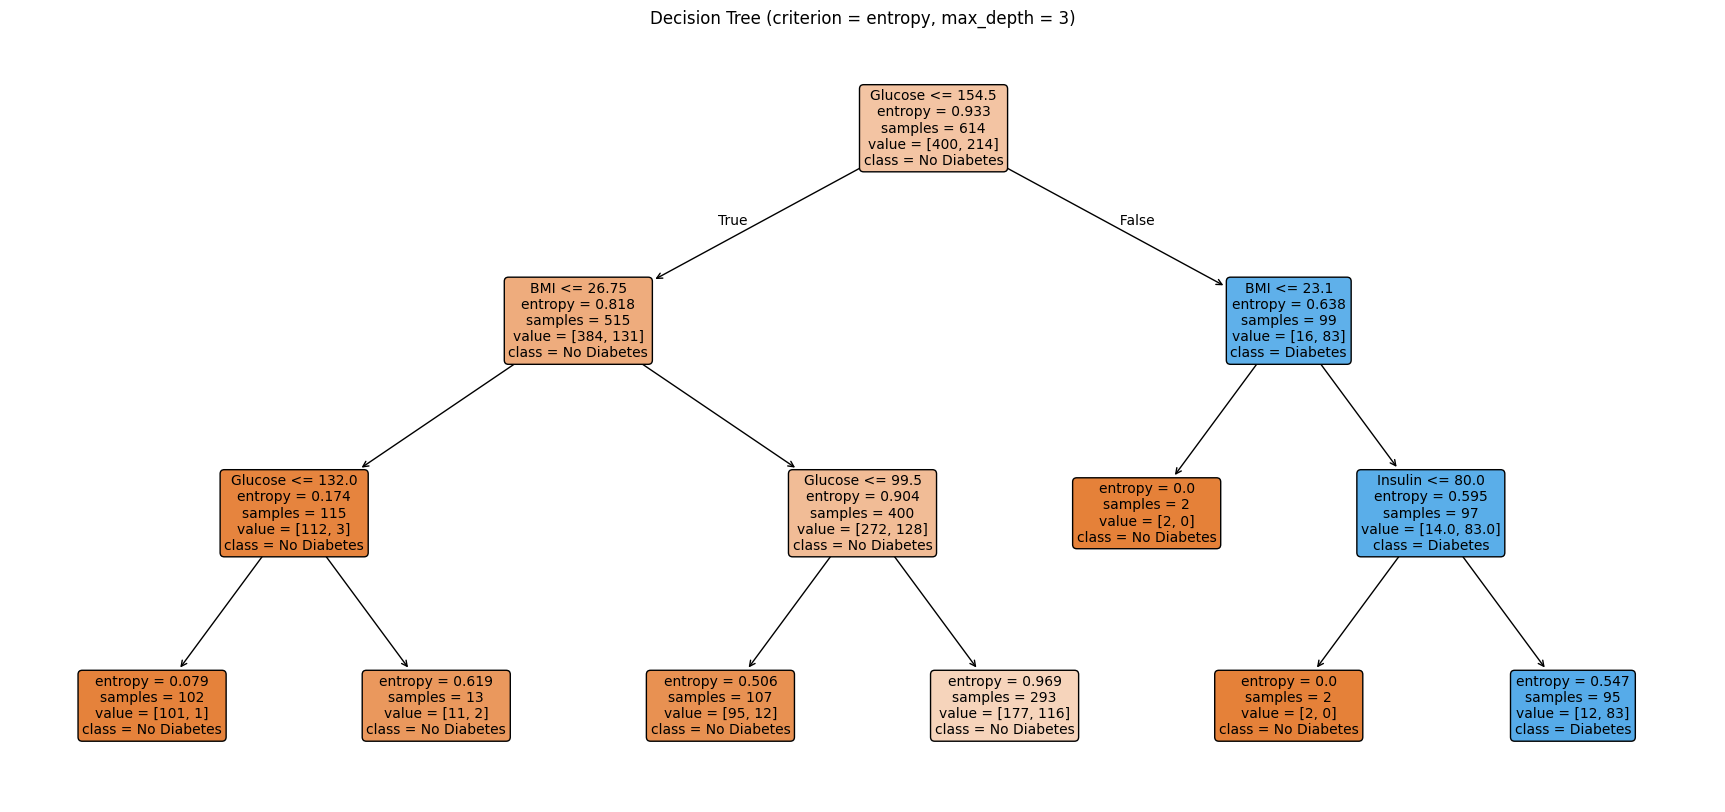

|--- Glucose <= 154.50
|   |--- BMI <= 26.75
|   |   |--- Glucose <= 132.00
|   |   |   |--- class: 0
|   |   |--- Glucose >  132.00
|   |   |   |--- class: 0
|   |--- BMI >  26.75
|   |   |--- Glucose <= 99.50
|   |   |   |--- class: 0
|   |   |--- Glucose >  99.50
|   |   |   |--- class: 0
|--- Glucose >  154.50
|   |--- BMI <= 23.10
|   |   |--- class: 0
|   |--- BMI >  23.10
|   |   |--- Insulin <= 80.00
|   |   |   |--- class: 0
|   |   |--- Insulin >  80.00
|   |   |   |--- class: 1



In [ ]:
plt.figure(figsize=(22,10))
plot_tree(clf, feature_names=X.columns, class_names=["No Diabetes","Diabetes"],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree (criterion = entropy, max_depth = 3)")
plt.show()

print(export_text(clf, feature_names=list(X.columns)))

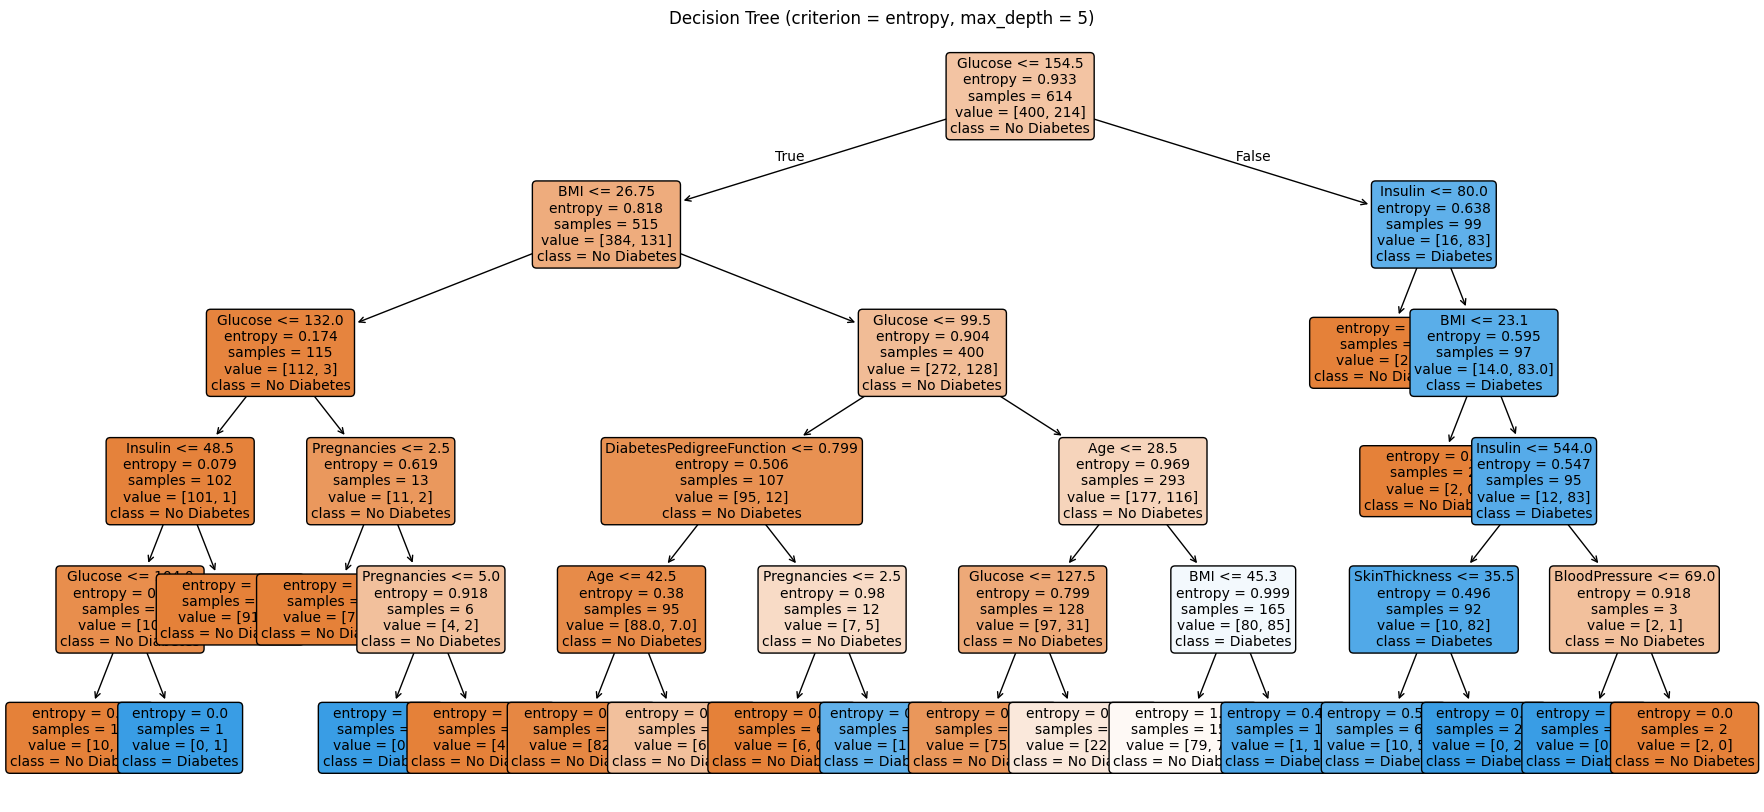

|--- Glucose <= 154.50
|   |--- BMI <= 26.75
|   |   |--- Glucose <= 132.00
|   |   |   |--- Insulin <= 48.50
|   |   |   |   |--- Glucose <= 104.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Glucose >  104.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- Insulin >  48.50
|   |   |   |   |--- class: 0
|   |   |--- Glucose >  132.00
|   |   |   |--- Pregnancies <= 2.50
|   |   |   |   |--- class: 0
|   |   |   |--- Pregnancies >  2.50
|   |   |   |   |--- Pregnancies <= 5.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Pregnancies >  5.00
|   |   |   |   |   |--- class: 0
|   |--- BMI >  26.75
|   |   |--- Glucose <= 99.50
|   |   |   |--- DiabetesPedigreeFunction <= 0.80
|   |   |   |   |--- Age <= 42.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Age >  42.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- DiabetesPedigreeFunction >  0.80
|   |   |   |   |--- Pregnancies <= 2.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Pregnancies

In [ ]:
clf = DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=42)

clf.fit(X_train, y_train)


plt.figure(figsize=(22, 10))

plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree (criterion = entropy, max_depth = 5)")
plt.show()

print(export_text(clf, feature_names=list(X.columns)))

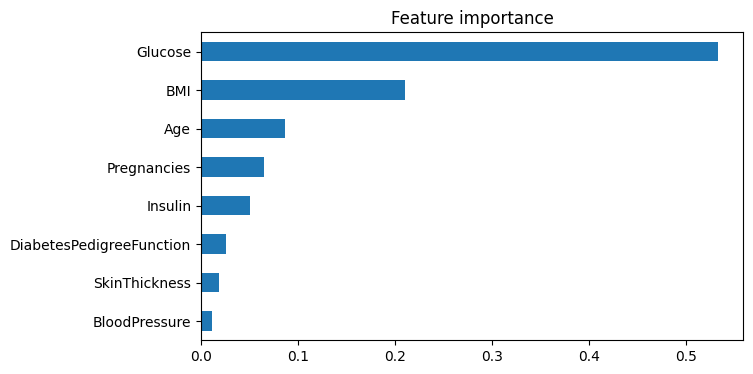

In [ ]:
pd.Series(clf.feature_importances_, index=X.columns).sort_values().plot(kind="barh", figsize=(7,4))
plt.title("Feature importance")
plt.show()

## 10. Why this root node? Entropy, Information Gain, Gini

In [ ]:
def entropy(s):
    p = s.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def gini(s):
    p = s.value_counts(normalize=True)
    return 1 - (p**2).sum()

def best_split(Xd, yd, feature):
    parent_e, parent_g = entropy(yd), gini(yd)
    best = dict(gain=0, thr=None, gini_drop=0)
    vals = np.sort(Xd[feature].unique())
    for t in (vals[:-1] + vals[1:]) / 2:
        left, right = yd[Xd[feature] <= t], yd[Xd[feature] > t]
        if len(left) == 0 or len(right) == 0:
            continue
        w = len(left) / len(yd)
        gain = parent_e - (w*entropy(left) + (1-w)*entropy(right))
        if gain > best["gain"]:
            g_after = w*gini(left) + (1-w)*gini(right)
            best = dict(gain=gain, thr=t, gini_drop=parent_g - g_after)
    return best

print("Parent entropy:", round(entropy(y_train),4))
print("Parent gini   :", round(gini(y_train),4))

res = []
for f in X_train.columns:
    b = best_split(X_train, y_train, f)
    res.append([f, b["thr"], round(b["gain"],4), round(b["gini_drop"],4)])

result = pd.DataFrame(res, columns=["Feature","Best threshold","Information Gain","Gini Reduction"])
result = result.sort_values("Information Gain", ascending=False).reset_index(drop=True)
result

Parent entropy: 0.9328
Parent gini   : 0.4541


,Feature,Best threshold,Information Gain,Gini Reduction
0,Glucose,154.5000,0.1436,0.0923
1,BMI,29.6500,0.0719,0.0418
2,Age,27.5000,0.0654,0.0394
3,Insulin,89.5000,0.0622,0.0317
4,Pregnancies,6.5000,0.0388,0.0254
5,SkinThickness,28.5000,0.0334,0.0201
6,BloodPressure,61.5000,0.0260,0.0148
7,DiabetesPedigreeFunction,0.5275,0.0243,0.0155


Glucose is selected as the root node because it has the highest Information Gain (0.1436) and Gini Reduction (0.0923). This means Glucose reduces uncertainty about diabetes prediction more than any other feature, making it the best starting point for splitting the data.

Root chosen by sklearn : Glucose <= 154.5
Root by my calculation : Glucose <= 154.5


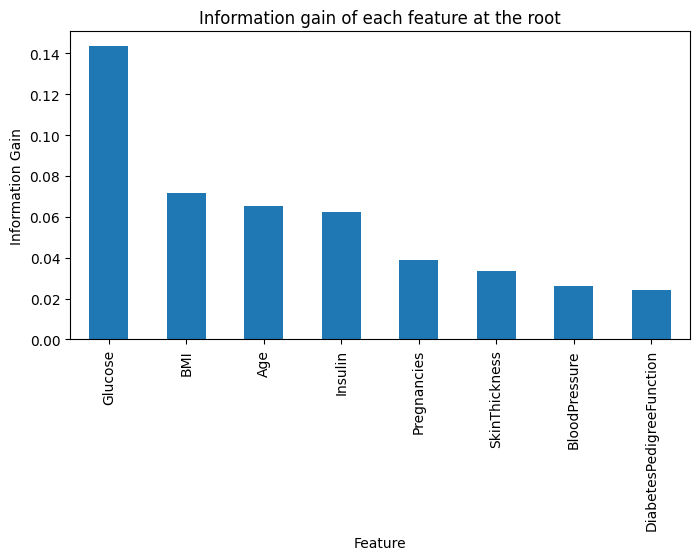

In [ ]:
root_feat = X.columns[clf.tree_.feature[0]]
root_thr  = clf.tree_.threshold[0]
print("Root chosen by sklearn :", root_feat, "<=", round(root_thr,2))
print("Root by my calculation :", result.loc[0, "Feature"], "<=", round(result.loc[0, "Best threshold"],2))

result.plot(x="Feature", y="Information Gain", kind="bar", legend=False, figsize=(8,4))
plt.title("Information gain of each feature at the root")
plt.ylabel("Information Gain")
plt.show()

Identify the best root node

Result: Glucose ≤ 154.5 is selected because it has the highest Information Gain (0.1436)

In [ ]:
f, t = root_feat, root_thr
left, right = y_train[X_train[f] <= t], y_train[X_train[f] > t]
w = len(left) / len(y_train)

print(f"Split: {f} <= {t:.2f}")
print(f"Parent : n={len(y_train)}, entropy={entropy(y_train):.4f}, gini={gini(y_train):.4f}")
print(f"Left   : n={len(left)}  (no={sum(left==0)}, yes={sum(left==1)}), entropy={entropy(left):.4f}, gini={gini(left):.4f}")
print(f"Right  : n={len(right)} (no={sum(right==0)}, yes={sum(right==1)}), entropy={entropy(right):.4f}, gini={gini(right):.4f}")

w_ent  = w*entropy(left) + (1-w)*entropy(right)
w_gini = w*gini(left)    + (1-w)*gini(right)
print(f"\nWeighted child entropy = {w_ent:.4f}")
print(f"Information Gain       = {entropy(y_train):.4f} - {w_ent:.4f} = {entropy(y_train)-w_ent:.4f}")
print(f"Weighted child gini    = {w_gini:.4f}")
print(f"Gini reduction         = {gini(y_train):.4f} - {w_gini:.4f} = {gini(y_train)-w_gini:.4f}")

Split: Glucose <= 154.50
Parent : n=614, entropy=0.9328, gini=0.4541
Left   : n=515  (no=384, yes=131), entropy=0.8181, gini=0.3793
Right  : n=99 (no=16, yes=83), entropy=0.6382, gini=0.2710

Weighted child entropy = 0.7891
Information Gain       = 0.9328 - 0.7891 = 0.1436
Weighted child gini    = 0.3619
Gini reduction         = 0.4541 - 0.3619 = 0.0923


The split creates two groups:

Glucose ≤ 154.5: 515 people, including 131 with diabetes.

Glucose > 154.5: 99 people, including 83 with diabetes

Overall Conclusion

The Decision Tree analysis identifies Glucose as the best root node, with a splitting threshold of 154.5, because it has the highest Information Gain (0.1436) and Gini Reduction (0.0923). The first code compares features to find the best split, while the last code verifies this choice by calculating the entropy and Gini impurity before and after splitting. The split creates two groups: people with Glucose ≤ 154.5 and people with Glucose > 154.5. The results show that the second group has a higher proportion of diabetes cases. Therefore, Glucose is the most effective feature for the first split in this dataset, helping the model distinguish between people with and without diabetes.